# 03 — Faster R-CNN & RetinaNet

Torchvision R50-FPN v2, COCO-pretrained, protocol P0 (1.5 GPU-h each, batch 2).

| run | change vs parent |
|---|---|
| `frcnn-e0` | baseline |
| `frcnn-e1` | RPN proposals 4000/2000 (train) & 2000/2000 (test), RoI batch 1024 @ 0.33 positives, anchors 16–256 px |
| `frcnn-e2` | + GIoU RoI box loss |
| `retina-e0` | baseline (default anchors, focal γ=2, α=0.25) |
| `retina-e1` | k-means anchors 10–109 px |
| `retina-e2` | + focal γ=1.5, matcher IoU 0.4/0.3, GIoU box loss |
| `retina-e3` | baseline anchors + focal γ=1.5, matcher IoU 0.4/0.3, GIoU box loss (added after `retina-e1`: separates the loss/matching effect from the anchor change) |

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
TV_COMMON = dict(
    seed=42, cache="k5_drop_L1920", k=5, imgsz=1280, min_size=720, max_size=1280, num_classes=9,
    trainable_backbone_layers=3, batch=2, workers=2, epochs=8, time_budget_h=1.5,
    optimizer="sgd", lr=0.005, momentum=0.9, weight_decay=0.0001, warmup_epochs=1.0, grad_clip_norm=10.0,
    augmentation=dict(hflip=0.5, scale_min=0.5, scale_max=1.0, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3),
    inference=dict(conf_thresh=0.001, nms_iou=0.6, max_det=500, slim_conf_thresh=0.05),
)

## 1. Faster R-CNN

In [3]:
FRCNN_E0 = dict(TV_COMMON, run_id="frcnn-e0", family="faster_rcnn", exp="e0", parent_run="",
    hypothesis="COCO-pretrained Faster R-CNN ResNet50-FPN v2 baseline (min_size=720, max_size=1280, 500 dets/img, 1.5 GPU-h budget).",
    rpn_pre_nms_top_n_train=2000, rpn_pre_nms_top_n_test=1000, rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=1000,
    box_batch_size_per_image=512, box_positive_fraction=0.25, roi_box_loss="smooth_l1")
FRCNN_E1 = dict(FRCNN_E0, run_id="frcnn-e1", exp="e1", parent_run="frcnn-e0",
    hypothesis="Doubling RPN pre/post-NMS proposals and expanding RoI batch size to 1024 (positive_fraction=0.33) with halved base anchor sizes (16..256 px) prevents RPN proposal starvation on crowded aerial frames.",
    rpn_pre_nms_top_n_train=4000, rpn_pre_nms_top_n_test=2000, rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=2000,
    box_batch_size_per_image=1024, box_positive_fraction=0.33, rpn_anchor_sizes=[[16], [32], [64], [128], [256]])
FRCNN_E2 = dict(FRCNN_E1, run_id="frcnn-e2", exp="e2", parent_run="frcnn-e1",
    hypothesis="Replacing Smooth-L1 RoI regression loss with scale-invariant GIoU loss on decoded boxes directly optimizes IoU across multi-scale aerial targets and improves AP75 and overall AP.",
    roi_box_loss="giou")

for cfg in (FRCNN_E0, FRCNN_E1, FRCNN_E2):
    train_torchvision_run(cfg)

[frcnn-e0] training completed earlier (frcnn-e0_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,val_AP,val_AP50,val_APs
0,1,0.2761,0.00500,1.03988,0.2002,0.4312,0.0893
1,2,0.5546,0.00476,0.72663,0.2227,0.4444,0.0923
2,3,0.8346,0.00411,0.63931,0.2148,0.4371,0.0916
3,4,1.1146,0.00315,0.58333,0.2045,0.4081,0.0802
4,5,1.3940,0.00210,0.53270,0.1994,0.4046,0.0822
5,6,1.4242,0.00203,0.49316,0.2055,0.4104,0.0848


[frcnn-e0] AP=0.2193 | AP50=0.4410 | APs=0.0906 | AR500=0.4420 | epochs=6 | gpu_h=1.4242 | fps=12.56
[frcnn-e1] training completed earlier (frcnn-e1_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.3292,0.00500,1.08692,0.48866,0.44882,0.21378,0.45529,0.10720
1,2,0.6616,0.00476,0.83303,0.44843,0.31506,0.20933,0.42973,0.10483
2,3,0.9936,0.00411,0.73816,0.41402,0.26981,0.20714,0.43331,0.09592
3,4,1.3266,0.00315,0.67652,0.38637,0.24405,0.20929,0.42702,0.11576
4,5,1.4282,0.00288,0.62521,0.36328,0.22168,0.20193,0.42396,0.09055


[frcnn-e1] AP=0.2154 | AP50=0.4609 | APs=0.1050 | AR500=0.4376 | epochs=5 | gpu_h=1.4282 | fps=9.69
[frcnn-e2] training completed earlier (frcnn-e2_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.3382,0.00500,0.67158,0.07053,0.45039,0.19086,0.40633,0.08695
1,2,0.6773,0.00476,0.45336,0.06402,0.31899,0.21965,0.45619,0.09651
2,3,1.0175,0.00411,0.39117,0.06124,0.27475,0.22253,0.46223,0.10580
3,4,1.3578,0.00315,0.35512,0.05928,0.24878,0.20968,0.43886,0.09809
4,5,1.4285,0.00298,0.32561,0.05755,0.22674,0.20932,0.43485,0.09664


[frcnn-e2] AP=0.2237 | AP50=0.4654 | APs=0.1050 | AR500=0.3932 | epochs=5 | gpu_h=1.4285 | fps=9.58


## 2. RetinaNet

In [4]:
RETINA_E0 = dict(TV_COMMON, run_id="retina-e0", family="retinanet", exp="e0", parent_run="",
    hypothesis="COCO-pretrained RetinaNet ResNet50-FPN v2 baseline (default 32-512 anchors, focal loss gamma=2.0/alpha=0.25, 500 dets/img, 1.5 GPU-h budget).",
    topk_candidates=1000, use_kmeans_anchors=False)
RETINA_E1 = dict(RETINA_E0, run_id="retina-e1", exp="e1", parent_run="retina-e0",
    hypothesis="Replacing COCO default anchors (mean best IoU 0.648) with 1280-scale k-means anchors (10..109 px, mean best IoU 0.819, 9 anchors/location) increases positive anchor matches on small VisDrone objects.",
    use_kmeans_anchors=True)
RETINA_E2 = dict(RETINA_E1, run_id="retina-e2", exp="e2", parent_run="retina-e1",
    hypothesis="Relaxing anchor positive/negative IoU thresholds from 0.5/0.4 to 0.4/0.3 with focal gamma=1.5, alpha=0.25 and GIoU box regression prevents tiny aerial objects from being starved of positive anchors.",
    focal_alpha=0.25, focal_gamma=1.5, fg_iou_thresh=0.4, bg_iou_thresh=0.3, box_loss_type="giou")
RETINA_E3 = dict(RETINA_E0, run_id="retina-e3", exp="e3", parent_run="retina-e0",
    hypothesis="Exp B alone: relaxed matcher IoU thresholds 0.4/0.3, focal gamma=1.5, alpha=0.25 and GIoU box regression with the default COCO anchors. Added after retina-e1 showed that the k-means anchors hurt, to separate the loss/matching effect from the anchor change.",
    focal_alpha=0.25, focal_gamma=1.5, fg_iou_thresh=0.4, bg_iou_thresh=0.3, box_loss_type="giou")

for cfg in (RETINA_E0, RETINA_E1, RETINA_E2, RETINA_E3):
    train_torchvision_run(cfg)

[retina-e0] training completed earlier (retina-e0_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.2133,0.00500,0.67908,0.25656,0.42252,0.14240,0.27401,0.05635
1,2,0.4247,0.00476,0.43744,0.23268,0.20476,0.16217,0.31485,0.06230
2,3,0.6362,0.00411,0.39216,0.22201,0.17015,0.16625,0.32184,0.06645
3,4,0.8479,0.00315,0.36580,0.21512,0.15068,0.17183,0.33363,0.06117
4,5,1.0646,0.00210,0.34816,0.20978,0.13838,0.16889,0.32984,0.06649
5,6,1.2843,0.00114,0.33547,0.20582,0.12965,0.16789,0.32306,0.06705
6,7,1.4211,0.00070,0.32927,0.20420,0.12506,0.16776,0.32443,0.06120


[retina-e0] AP=0.1731 | AP50=0.3352 | APs=0.0583 | AR500=0.3375 | epochs=7 | gpu_h=1.4211 | fps=18.45
[retina-e1] training completed earlier (retina-e1_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.2182,0.00500,1.10105,0.45677,0.64428,0.02955,0.10174,0.03249
1,2,0.4416,0.00476,0.75034,0.37166,0.37868,0.04900,0.16295,0.03720
2,3,0.6564,0.00411,0.66574,0.34257,0.32316,0.05579,0.17551,0.03997
3,4,0.8703,0.00315,0.61769,0.32527,0.29242,0.06266,0.18591,0.04022
4,5,1.0843,0.00210,0.58445,0.31318,0.27127,0.06885,0.20327,0.04147
5,6,1.2984,0.00114,0.56037,0.30361,0.25677,0.06890,0.19766,0.03991
6,7,1.4207,0.00074,0.54656,0.29777,0.24879,0.06959,0.19971,0.04134


[retina-e1] AP=0.0686 | AP50=0.1993 | APs=0.0383 | AR500=0.2548 | epochs=7 | gpu_h=1.4207 | fps=18.68
[retina-e2] training completed earlier (retina-e2_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.2132,0.00500,1.21475,0.48857,0.72618,0.03215,0.10618,0.04012
1,2,0.4243,0.00476,0.80170,0.38645,0.41525,0.04900,0.15425,0.04212
2,3,0.6342,0.00411,0.70614,0.35745,0.34869,0.05427,0.16608,0.04045
3,4,0.8448,0.00315,0.64824,0.34005,0.30819,0.06408,0.19031,0.04432
4,5,1.0567,0.00210,0.60856,0.32721,0.28135,0.06736,0.20093,0.04397
5,6,1.2672,0.00114,0.58134,0.31819,0.26315,0.06781,0.19952,0.04202
6,7,1.4208,0.00064,0.56358,0.31231,0.25127,0.07073,0.20766,0.04552


[retina-e2] AP=0.0694 | AP50=0.2054 | APs=0.0448 | AR500=0.2411 | epochs=7 | gpu_h=1.4208 | fps=17.97
[retina-e3] training completed earlier (retina-e3_best.pth); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.2108,0.00500,0.73286,0.27131,0.46154,0.11639,0.21265,0.04017
1,2,0.4213,0.00476,0.45310,0.23935,0.21374,0.12914,0.24963,0.04934
2,3,0.6321,0.00411,0.39771,0.22667,0.17105,0.13624,0.25579,0.05082
3,4,0.8446,0.00315,0.36613,0.21843,0.14770,0.14016,0.26198,0.04921
4,5,1.0570,0.00210,0.34474,0.21247,0.13227,0.13320,0.25044,0.04306
5,6,1.2688,0.00114,0.33044,0.20817,0.12227,0.13693,0.25658,0.04197
6,7,1.4205,0.00064,0.32202,0.20587,0.11615,0.13360,0.25083,0.03952


[retina-e3] AP=0.1424 | AP50=0.2664 | APs=0.0473 | AR500=0.2543 | epochs=7 | gpu_h=1.4205 | fps=18.36


## 3. Results (val)

In [5]:
F12 = ["frcnn-e0", "frcnn-e1", "frcnn-e2", "retina-e0", "retina-e1", "retina-e2", "retina-e3"]
display(results_table(run_ids=F12).round(4))
cls_cols = ["run_id"] + [f"ap_{c}" for c in ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]]
display(results_table(run_ids=F12, cols=cls_cols).round(3))
for rid in F12:
    log = training_log(rid)
    if not log.empty:
        print(rid, "— proxy-val mAP per epoch:", log["val_AP"].round(4).tolist())

,run_id,family,exp,imgsz,epochs_done,gpu_h,AP,AP50,AP75,APs,APm,APl,AR500,fps
0,frcnn-e0,faster_rcnn,e0,1280,6,1.4242,0.2193,0.4410,0.1938,0.0906,0.2024,0.3900,0.4420,12.56
1,frcnn-e1,faster_rcnn,e1,1280,5,1.4282,0.2154,0.4609,0.1704,0.1050,0.1997,0.3770,0.4376,9.69
2,frcnn-e2,faster_rcnn,e2,1280,5,1.4285,0.2237,0.4654,0.1862,0.1050,0.2104,0.3965,0.3932,9.58
3,retina-e0,retinanet,e0,1280,7,1.4211,0.1731,0.3352,0.1555,0.0582,0.1591,0.3183,0.3375,18.45
4,retina-e1,retinanet,e1,1280,7,1.4207,0.0686,0.1993,0.0264,0.0383,0.0758,0.0864,0.2548,18.68
5,retina-e2,retinanet,e2,1280,7,1.4208,0.0694,0.2054,0.0278,0.0448,0.0762,0.0832,0.2411,17.97
6,retina-e3,retinanet,e3,1280,7,1.4205,0.1424,0.2664,0.1336,0.0473,0.1268,0.2866,0.2543,18.36


,run_id,ap_person,ap_bicycle,ap_car,ap_van,ap_truck,ap_tricycle,ap_bus,ap_motor
0,frcnn-e0,0.271,0.239,0.349,0.226,0.200,0.224,0.133,0.112
1,frcnn-e1,0.275,0.246,0.387,0.210,0.259,0.189,0.018,0.139
2,frcnn-e2,0.280,0.228,0.388,0.238,0.266,0.235,0.026,0.129
3,retina-e0,0.241,0.157,0.337,0.174,0.222,0.144,0.012,0.100
4,retina-e1,0.136,0.058,0.156,0.064,0.013,0.055,0.000,0.065
5,retina-e2,0.144,0.069,0.155,0.060,0.010,0.050,0.000,0.067
6,retina-e3,0.177,0.100,0.299,0.174,0.172,0.156,0.002,0.058


frcnn-e0 — proxy-val mAP per epoch: [0.2002, 0.2227, 0.2148, 0.2045, 0.1994, 0.2055]
frcnn-e1 — proxy-val mAP per epoch: [0.2138, 0.2093, 0.2071, 0.2093, 0.2019]
frcnn-e2 — proxy-val mAP per epoch: [0.1909, 0.2196, 0.2225, 0.2097, 0.2093]
retina-e0 — proxy-val mAP per epoch: [0.1424, 0.1622, 0.1663, 0.1718, 0.1689, 0.1679, 0.1678]
retina-e1 — proxy-val mAP per epoch: [0.0296, 0.049, 0.0558, 0.0627, 0.0689, 0.0689, 0.0696]
retina-e2 — proxy-val mAP per epoch: [0.0322, 0.049, 0.0543, 0.0641, 0.0674, 0.0678, 0.0707]
retina-e3 — proxy-val mAP per epoch: [0.1164, 0.1291, 0.1362, 0.1402, 0.1332, 0.1369, 0.1336]


**Notes.** Faster R-CNN: best `frcnn-e2` (AP 0.2237; GIoU adds +0.008 AP over `e1`); proxy-val mAP peaks at epoch 2–3 and then declines (best-epoch checkpoints are evaluated). RetinaNet: best is the baseline `retina-e0` (0.1731). The k-means anchors (`e1`, 10–109 px) collapse AP75 (0.026) and AP_large (0.086), and `e2` on top of them does not recover; the focal/matcher/GIoU changes alone (`e3`) also lower AP (0.1424). Tuned two-stage vs best one-stage: +0.051 AP and AP_small 0.105 vs 0.058, at 9.6 vs 18.5 FPS.

## 4. RPN proposal recall@K (IoU ≥ 0.5)

In [6]:
from vdet.utils import load_json
rows = []
for rid in ["frcnn-e0", "frcnn-e1", "frcnn-e2"]:
    pth = P.exp_runs_dir / rid / "rpn_recall.json"
    if pth.exists():
        s = run_summary(rid) or {}
        rows.append({"run_id": rid, **load_json(pth), "AR500 (final dets)": s.get("AR500"), "AP": s.get("AP")})
rpn = pd.DataFrame(rows)
display(rpn.round(4))

,run_id,total_gt,total_gt_small,rpn_recall@300,rpn_small_recall@300,rpn_recall@1000,rpn_small_recall@1000,rpn_recall@2000,rpn_small_recall@2000,AR500 (final dets),AP
0,frcnn-e0,4937.0,1321.0,0.8489,0.7456,0.8608,0.7517,0.8608,0.7517,0.4420,0.2193
1,frcnn-e1,4937.0,1321.0,0.8754,0.7820,0.9400,0.8986,0.9581,0.9296,0.4376,0.2154
2,frcnn-e2,4937.0,1321.0,0.8527,0.7494,0.9273,0.8925,0.9530,0.9326,0.3932,0.2237


**Notes.** More proposals and finer anchors (`e1`, `e2`) raise RPN recall@1000 from 0.86 to 0.93–0.94 and small-object recall from 0.75 to 0.89–0.90 (AP_small 0.091 → 0.105), at the cost of speed (9.6–9.7 vs 12.6 FPS).

## 5. Comparison with YOLO11 and RT-DETR by object size

,run_id,AP,APs,APm,APl,AR500,fps,gpu_h,epochs_done
0,frcnn-e0,0.2193,0.0906,0.2024,0.3900,0.4420,12.56,1.4242,6
1,frcnn-e1,0.2154,0.1050,0.1997,0.3770,0.4376,9.69,1.4282,5
2,frcnn-e2,0.2237,0.1050,0.2104,0.3965,0.3932,9.58,1.4285,5
3,retina-e0,0.1731,0.0582,0.1591,0.3183,0.3375,18.45,1.4211,7
4,retina-e1,0.0686,0.0383,0.0758,0.0864,0.2548,18.68,1.4207,7
5,retina-e2,0.0694,0.0448,0.0762,0.0832,0.2411,17.97,1.4208,7
6,retina-e3,0.1424,0.0473,0.1268,0.2866,0.2543,18.36,1.4205,7
7,yolo-e0,0.2067,0.1085,0.2080,0.3103,0.3291,55.73,1.5038,15
8,yolo-e1,0.2184,0.1312,0.2068,0.3465,0.3716,32.52,1.5039,11
9,rtdetr-e0,0.2654,0.1370,0.2378,0.4439,0.4329,9.04,1.5184,3


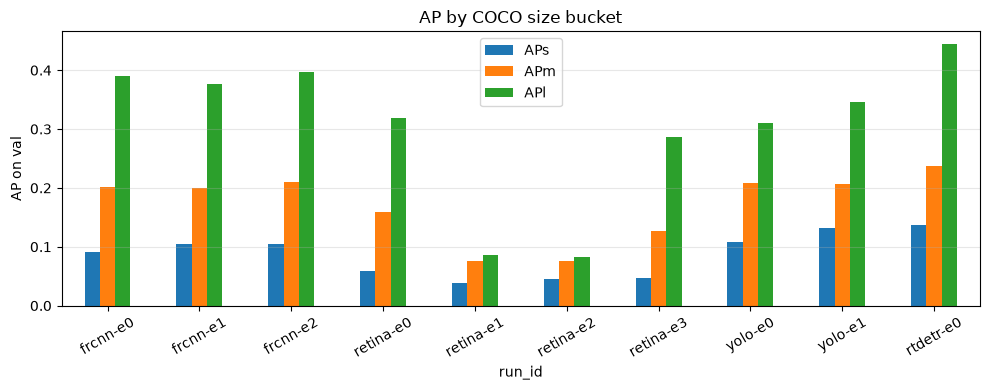

In [7]:
best = ["frcnn-e0", "frcnn-e1", "frcnn-e2", "retina-e0", "retina-e1", "retina-e2", "retina-e3", "yolo-e0", "yolo-e1", "rtdetr-e0"]
size_tbl = results_table(run_ids=best, cols=["run_id", "AP", "APs", "APm", "APl", "AR500", "fps", "gpu_h", "epochs_done"])
display(size_tbl.round(4))
ax = size_tbl.set_index("run_id")[["APs", "APm", "APl"]].plot.bar(figsize=(10, 4), rot=30)
ax.set_ylabel("AP on val"); ax.set_title("AP by COCO size bucket"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Failure cases

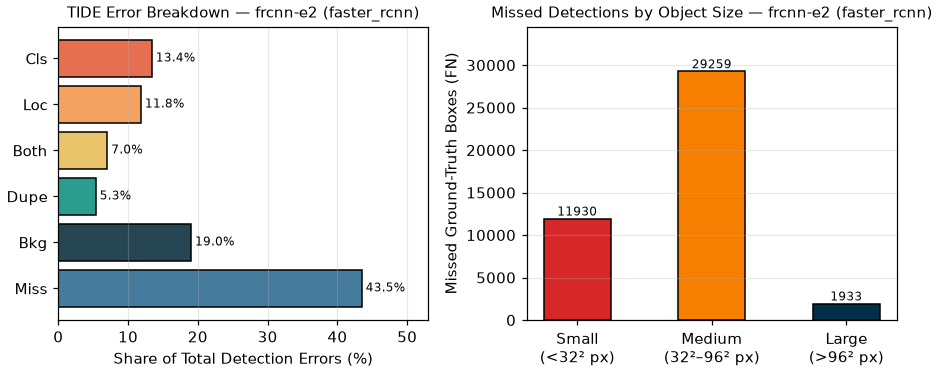

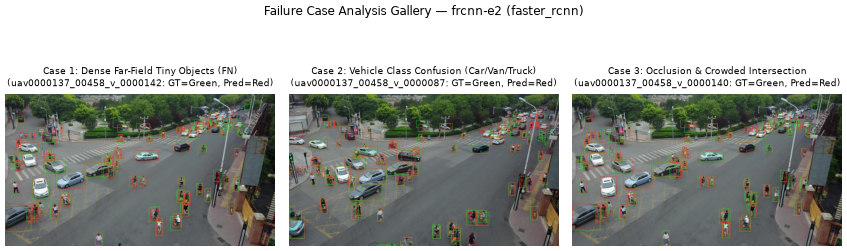

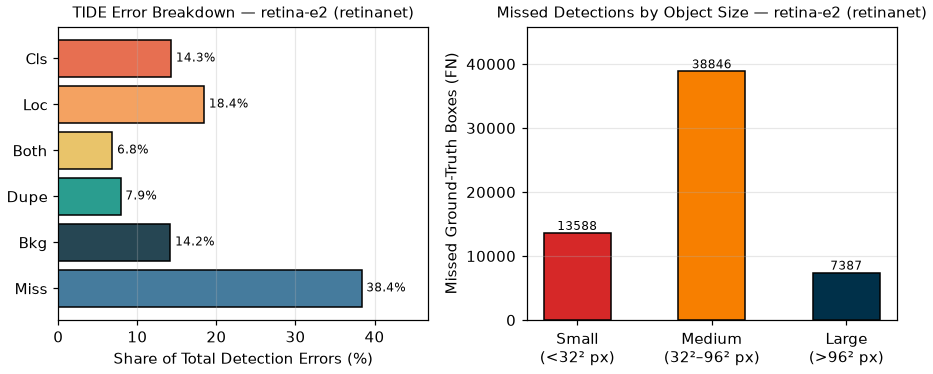

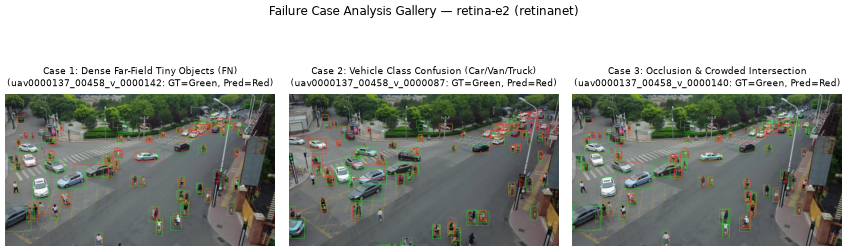

,TP,Cls,Loc,Both,Dupe,Bkg,Miss,Miss_small,Miss_medium,Miss_large
frcnn-e2,71010,13273,11731,6948,5295,18858,43122,11930,29259,1933
retina-e0,65644,25641,18497,6290,13356,20709,48488,13476,32797,2215


In [8]:
from vdet.eval.errors import compute_tide_breakdown, plot_failure_gallery, plot_tide_breakdown

def best_run(cands):
    runs = [(run_summary(r) or {}).get("AP") for r in cands]
    scored = [(a, r) for a, r in zip(runs, cands) if a not in (None, "") and (P.runs / r / "preds_val.parquet").exists()]
    return max(scored)[1] if scored else None

tide_rows = {}
for fam, cands in [("faster_rcnn", ["frcnn-e0", "frcnn-e1", "frcnn-e2"]), ("retinanet", ["retina-e0", "retina-e1", "retina-e2", "retina-e3"])]:
    rid = best_run(cands)
    if rid is None:
        continue
    preds = pd.read_parquet(P.runs / rid / "preds_val.parquet")
    tide = compute_tide_breakdown(preds, split="val", conf_thresh=0.20, top_k_per_frame=100)
    tide_rows[rid] = tide["counts"]
    for name, fn in [(f"tide_{fam}.png", lambda: plot_tide_breakdown(tide, f"{rid} ({fam})", P.images / f"tide_{fam}.png")),
                     (f"failures_{fam}.png", lambda: plot_failure_gallery(preds, f"{rid} ({fam})", P.images / f"failures_{fam}.png"))]:
        if not (P.images / name).exists():
            fn()
        show_image(name, 900)
display(pd.DataFrame(tide_rows).T)